In [12]:
# =============================================================================
# CELL 1 - Configuration
# Every tunable setting lives here. Change values here, not inside later cells.
# =============================================================================
from types import SimpleNamespace

CFG = SimpleNamespace(
    # --- Data ---
    input_root   = r"X:\aanand37\Manuscript\Snapshot Wisconsin\data",
    csv_name     = "Qwen_model\Qwen_model_visible_only_for_head_visibility.csv",
    photos_sub   = os.path.join("Snapshot_WI-Oh_Deer_Photos", "Deer") if "os" in dir() else r"Snapshot_WI-Oh_Deer_Photos\Deer",
    # Column that groups near-duplicate images (e.g. camera site, burst/sequence id).
    # All images in a group go to the same split so they can't leak between train and test.
    # None = group by image file only (prevents multi-deer rows of one photo from being split).
    group_col    = None,

    # --- Preprocessing ---
    img_size     = 256,
    use_bbox     = True,          # crop to the deer using the CSV's bounding box
    bbox_pad     = 0.15,          # enlarge the box by 15% on each side before cropping

    # --- Model ---
    model_name   = "efficientnet_b0", #"efficientnet_b0",   # any timm model, e.g. "convnext_nano"
    dropout      = 0.3,

    # --- Optimisation ---
    epochs       = 50,            # maximum; early stopping usually ends sooner
    batch_size   = 32,
    lr           = 3e-4,          # peak learning rate (reached after warmup)
    weight_decay = 1e-4,
    warmup_epochs = 1,            # linear LR warmup from ~0 to lr
    label_smooth = 0.05,
    grad_clip    = 1.0,           # max gradient norm; None to disable
    amp          = True,          # mixed precision

    # --- LR reduction on plateau (after warmup) ---
    plateau_factor   = 0.3,       # multiply LR by this when val F1 stalls
    plateau_patience = 2,         # epochs without improvement before reducing LR
    min_lr           = 1e-6,

    # --- Early stopping ---
    patience     = 5,             # epochs without improvement before stopping (> plateau_patience,
                                  # so LR gets reduced at least twice before we give up)
    min_delta    = 1e-3,          # smallest val macro-F1 gain that counts as improvement

    # --- Splits ---
    val_frac     = 0.15,          # used for early stopping, LR schedule, threshold tuning
    test_frac    = 0.15,          # touched once, at the very end
    seed         = 42,

    # --- Runtime ---
    num_workers  = 2,             # forced to 0 on Windows (see Cell 2)
    log_every    = 1,             # print every N training batches (1 = every batch)
    tune_threshold = True,        # pick decision threshold on val to maximise macro-F1
    
    # --- Output ---
    out_dir      = r"X:\aanand37\Manuscript\Snapshot Wisconsin\data",
    model_file   = "antler_model.pt",
    pred_file    = "antler_test_predictions.csv",
)
print(CFG)

namespace(input_root='X:\\aanand37\\Manuscript\\Snapshot Wisconsin\\data', csv_name='Qwen_model\\Qwen_model_visible_only_for_head_visibility.csv', photos_sub='Snapshot_WI-Oh_Deer_Photos\\Deer', group_col=None, img_size=256, use_bbox=True, bbox_pad=0.15, model_name='efficientnet_b0', dropout=0.3, epochs=50, batch_size=32, lr=0.0003, weight_decay=0.0001, warmup_epochs=1, label_smooth=0.05, grad_clip=1.0, amp=True, plateau_factor=0.3, plateau_patience=2, min_lr=1e-06, patience=5, min_delta=0.001, val_frac=0.15, test_frac=0.15, seed=42, num_workers=2, log_every=1, tune_threshold=True, out_dir='X:\\aanand37\\Manuscript\\Snapshot Wisconsin\\data', model_file='antler_model.pt', pred_file='antler_test_predictions.csv')


In [13]:
# =============================================================================
# CELL 2 - Imports, reproducibility, GPU check
# =============================================================================
import sys, subprocess

def _pip(pkg):
    """Install a package into THIS kernel's Python, only if it's missing."""
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_pip("timm")

import os, re, glob, random, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # camera-trap JPEGs can be large; disable PIL's size guard

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
import sklearn
from sklearn.model_selection import train_test_split   # (StratifiedGroupKFold needs sklearn >= 1.0)
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

def seed_everything(seed):
    """Seed Python, NumPy and PyTorch RNGs so splits and initialisation are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(CFG.seed)

if not torch.cuda.is_available():
    raise RuntimeError(
        f"GPU required but CUDA is unavailable. Python: {sys.executable}; "
        f"torch {torch.__version__}; compiled CUDA: {torch.version.cuda}"
    )
torch.cuda.set_device(0)
DEVICE = "cuda"
torch.backends.cudnn.benchmark = True   # fixed input size -> cuDNN picks the fastest kernels

# In Jupyter on Windows, DataLoader worker processes can't import classes defined in the
# notebook and hang. Loading in the main process is slower but reliable.
if os.name == "nt":
    CFG.num_workers = 0

print(f"torch {torch.__version__} | timm {timm.__version__} | sklearn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"GPU: {torch.cuda.get_device_name(1)} | DataLoader workers: {CFG.num_workers} | AMP: {CFG.amp}") ## Change GPU name

torch 2.3.0+cu118 | timm 1.0.13 | sklearn 0.24.2 | pandas 2.0.3 | numpy 1.24.2
GPU: NVIDIA A100-PCIE-40GB | DataLoader workers: 0 | AMP: True



# 3. Load data & auto-detect the schema
The dataset is one CSV (a row per image, 10 columns, including a bounding box) plus a folder of ~4,880 JPGs.

Because a real-world CSV rarely has exactly the column names you expect, the cell below auto-detects which columns hold the filename, the Antlers label, the Age label, and the bounding box — by fuzzy keyword matching. It prints what it found so you can sanity-check. If it guesses wrong, override the COLS dict manually.

In [14]:
# =============================================================================
# CELL 3 - Locate and load the data
# =============================================================================
CFG.csv_path   = os.path.join(CFG.input_root, CFG.csv_name)
CFG.photos_dir = os.path.join(CFG.input_root, "Snapshot_WI-Oh_Deer_Photos", "Deer")

if not os.path.isfile(CFG.csv_path):
    raise FileNotFoundError(f"CSV not found: {CFG.csv_path}")
if not os.path.isdir(CFG.photos_dir):
    raise FileNotFoundError(f"Photo folder not found: {CFG.photos_dir}")

n_jpgs = len(glob.glob(os.path.join(CFG.photos_dir, "*.jpg")))
print(f"CSV      : {CFG.csv_path}")
print(f"Photos   : {CFG.photos_dir} ({n_jpgs} .jpg files)")

df = pd.read_csv(CFG.csv_path)
print(f"CSV shape: {df.shape}")
print(f"Columns  : {list(df.columns)}")
print(df.head())

CSV      : X:\aanand37\Manuscript\Snapshot Wisconsin\data\Qwen_model\Qwen_model_visible_only_for_head_visibility.csv
Photos   : X:\aanand37\Manuscript\Snapshot Wisconsin\data\Snapshot_WI-Oh_Deer_Photos\Deer (4880 .jpg files)
CSV shape: (4537, 17)
Columns  : ['row_id', 'filename', 'year', 'month', 'bbox_origin_x', 'bbox_origin_y', 'bbox_width', 'bbox_height', 'bbox_confidence', 'antler_status', 'age_status', 'head_visibility', 'status', 'fallback', 'attempts', 'finish_reason', 'error']
   row_id                  filename  year  month  bbox_origin_x  \
0       0  SSWI000000027884533B.jpg  2022      6         0.2687   
1       1  SSWI000000019469717A.jpg  2020      9         0.4831   
2       3  SSWI000000010695719B.jpg  2018      8         0.2587   
3       4  SSWI000000020110273C.jpg  2020      8         0.2068   
4       5  SSWI000000011340915C.jpg  2018      8         0.1943   

   bbox_origin_y  bbox_width  bbox_height  bbox_confidence antler_status  \
0         0.1066      0.5043   

In [15]:
# =============================================================================
# CELL 4 - Detect the columns we need
# =============================================================================
def find_col(df, keywords, exclude=()):
    """Return the column that best matches the EARLIEST keyword in `keywords`.

    - Keywords of <= 2 characters (e.g. 'x', 'w', 'h') must match a whole token of the
      column name, so 'h' does NOT match inside 'width'.
    - Longer keywords match as substrings.
    - Columns containing any string in `exclude` are skipped.
    Returns None if nothing matches.
    """
    def tokens(c):
        return {t for t in re.split(r"[^a-z0-9]+", c.lower()) if t}

    best, best_rank = None, float("inf")
    for c in df.columns:
        lc = c.lower()
        if any(x in lc for x in exclude):
            continue
        toks = tokens(c)
        for rank, k in enumerate(keywords):
            hit = (k in toks) if len(k) <= 2 else (k in lc)
            if hit:
                if rank < best_rank:
                    best, best_rank = c, rank
                break
    return best

COLS = {
    "image":  find_col(df, ["filename", "file", "image", "photo", "img", "name"],
                       exclude=["width", "height", "size"]),
    "antler": find_col(df, ["antler"]),
    # Bounding box: supports (x, y, w, h) and (xmin, ymin, xmax, ymax).
    # 'image'/'img' are excluded so image-dimension columns aren't taken as box size.
    "x":    find_col(df, ["xmin", "x_min", "left", "bbox_x", "x"], exclude=["max", "image", "img"]),
    "y":    find_col(df, ["ymin", "y_min", "top", "bbox_y", "y"],  exclude=["max", "image", "img"]),
    "w":    find_col(df, ["bbox_w", "width", "w"],  exclude=["image", "img"]),
    "h":    find_col(df, ["bbox_h", "height", "h"], exclude=["image", "img"]),
    "xmax": find_col(df, ["xmax", "x_max", "right"]),
    "ymax": find_col(df, ["ymax", "y_max", "bottom"]),
}

print("Detected columns:")
for k, v in COLS.items():
    print(f"  {k:7s} -> {v}")

for required in ("image", "antler"):
    if COLS[required] is None:
        raise KeyError(f"Could not detect the '{required}' column. Set COLS['{required}'] manually.")

print("\nCheck the mapping above. Override if wrong, e.g.  COLS['antler'] = 'AntlerStatus'")

Detected columns:
  image   -> filename
  antler  -> antler_status
  x       -> bbox_origin_x
  y       -> bbox_origin_y
  w       -> bbox_width
  h       -> bbox_height
  xmax    -> None
  ymax    -> None

Check the mapping above. Override if wrong, e.g.  COLS['antler'] = 'AntlerStatus'


In [16]:
# =============================================================================
# CELL 5 - Labels and image-file check -> `data` (the usable rows)
# =============================================================================
ANTLER_NAMES = ["Antlerless", "Antlered"]   # class index 0, class index 1

# Short codes must match the WHOLE value (so "10" is not read as "1").
# Words may appear anywhere in the value ("antlered buck" -> positive).
POS_EXACT = {"1", "1.0", "yes", "y", "true"}
NEG_EXACT = {"0", "0.0", "no", "n", "false"}
POS_WORDS = ["antlered", "buck"]
NEG_WORDS = ["antlerless", "doe"]

def normalize_label(series):
    """Map raw antler values to 1.0 (antlered), 0.0 (antlerless) or NaN (unknown / conflicting)."""
    def map_one(v):
        pos = v in POS_EXACT or any(w in v for w in POS_WORDS)
        neg = v in NEG_EXACT or any(w in v for w in NEG_WORDS)
        if pos and not neg:
            return 1.0
        if neg and not pos:
            return 0.0
        return np.nan                      # no match, or matched both lists
    return series.astype(str).str.strip().str.lower().map(map_one)

df["y_antler"] = normalize_label(df[COLS["antler"]])

# Show exactly how every raw value was mapped - VERIFY THIS before training.
raw = df[COLS["antler"]].astype(str).str.strip().str.lower()
mapped = df["y_antler"].map({1.0: "1 (Antlered)", 0.0: "0 (Antlerless)"}).fillna("NaN (dropped)")
print("Raw value -> mapped label:")
print(pd.DataFrame({"raw": raw, "mapped": mapped})
        .groupby(["raw", "mapped"]).size().rename("n")
        .sort_values(ascending=False).reset_index().to_string(index=False))

# Resolve image paths and check each file exists. A missing file must be dropped here,
# never replaced by a placeholder image during training.
def resolve(fn):
    fn = str(fn).strip()
    return fn if os.path.isabs(fn) else os.path.join(CFG.photos_dir, fn)

df["path"] = df[COLS["image"]].map(resolve)
df["file_exists"] = df["path"].map(os.path.isfile)

n_missing = int((~df["file_exists"]).sum())
if df["file_exists"].sum() == 0:
    raise FileNotFoundError(f"No image files found. Example path tried: {df['path'].iloc[0]}")
if n_missing:
    print(f"\n{n_missing} rows point to missing image files and will be dropped. Examples:")
    print(df.loc[~df["file_exists"], "path"].head().to_string(index=False))

data = df[df["y_antler"].notna() & df["file_exists"]].reset_index(drop=True).copy()
data["y_antler"] = data["y_antler"].astype(int)

print(f"\nUsable rows: {len(data)} of {len(df)} "
      f"({int(df['y_antler'].isna().sum())} unmapped labels, {n_missing} missing files)")
print(f"Unique image files: {data['path'].nunique()}")
print("Class counts:", {ANTLER_NAMES[k]: int(v) for k, v in data["y_antler"].value_counts().sort_index().items()})

Raw value -> mapped label:
       raw         mapped    n
antlerless 0 (Antlerless) 3193
  antlered   1 (Antlered) 1344

Usable rows: 4537 of 4537 (0 unmapped labels, 0 missing files)
Unique image files: 4537
Class counts: {'Antlerless': 3193, 'Antlered': 1344}


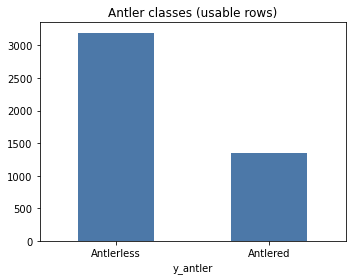

Estimated night (IR) fraction in a 200-image sample: 57%


In [17]:
# =============================================================================
# CELL 6 - Quick look: class balance and day/night mix
# =============================================================================
fig, ax = plt.subplots(figsize=(5, 4))
(data["y_antler"].map(dict(enumerate(ANTLER_NAMES)))
     .value_counts().reindex(ANTLER_NAMES)
     .plot.bar(ax=ax, color="#4C78A8", title="Antler classes (usable rows)"))
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

def is_night(path, thresh=12):
    """True if the image looks like an IR night shot (near-zero colour saturation).
    Returns None if the file can't be read."""
    try:
        with Image.open(path) as im:
            arr = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
        return bool((arr.max(-1) - arr.min(-1)).mean() < thresh)
    except Exception:
        return None

sample = data["path"].sample(min(200, len(data)), random_state=0)
flags = [f for f in (is_night(p) for p in sample) if f is not None]   # skip unreadable files
if flags:
    print(f"Estimated night (IR) fraction in a {len(flags)}-image sample: {np.mean(flags):.0%}")
else:
    print("No readable images in the sample.")

# 4. Exploratory data analysis
Two things drive the modelling choices here:

Class balance. F1 (not accuracy) is the metric precisely because these tags are imbalanced — most deer are Adult and, depending on season, most are Antlerless. A model that always predicts the majority class gets high accuracy but terrible F1. We'll counter this with class-weighted loss and threshold tuning.
Bounding-box coverage. Antlers are a fine detail. Cropping to the deer (using the provided box) removes distracting background and makes the antler signal far easier to learn.

# 5. Dataset, bounding-box cropping & augmentation
The DeerDataset reads an image, optionally crops to the deer using the bounding box (expanded by bbox_pad so we don't clip antlers), and applies augmentation. Both bbox conventions — (x, y, w, h) and (xmin, ymin, xmax, ymax) — and both normalized (0–1) and pixel coordinates are handled.

Augmentation is deliberately mild and label-preserving: horizontal flip (a flipped buck is still a buck), small rotation/scale/color jitter to simulate different cameras, lighting, and seasons.

In [18]:
# =============================================================================
# CELL 7 - Image loading (tolerates damaged JPEGs), bbox cropping, Dataset
# =============================================================================
from PIL import ImageFile

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def get_bbox(row, W, H):
    """Return (left, top, right, bottom) in pixels of the ORIGINAL image, or None."""
    c = COLS
    try:
        if c["x"] and c["y"] and c["xmax"] and c["ymax"]:            # corner format
            l, t, r, b = (float(row[c[k]]) for k in ("x", "y", "xmax", "ymax"))
        elif c["x"] and c["y"] and c["w"] and c["h"]:                  # x, y, width, height
            x, y, w, h = (float(row[c[k]]) for k in ("x", "y", "w", "h"))
            l, t, r, b = x, y, x + w, y + h
        else:
            return None
    except (ValueError, TypeError, KeyError):
        return None
    if not np.all(np.isfinite([l, t, r, b])):                          # NaN / inf box
        return None
    if max(l, t, r, b) <= 1.5:                                          # normalised 0-1 coords
        l, r, t, b = l * W, r * W, t * H, b * H
    if not (r > l and b > t):
        return None
    return l, t, r, b

def crop_to_bbox(img, box, pad):
    """Crop `img` to `box` enlarged by `pad` (fraction of box size), clipped to the image."""
    W, H = img.size
    l, t, r, b = box
    pw, ph = (r - l) * pad, (b - t) * pad
    l, t = max(0, l - pw), max(0, t - ph)
    r, b = min(W, r + pw), min(H, b + ph)
    return img.crop((int(l), int(t), int(r), int(b)))

def load_rgb(path):
    """Open an image as RGB in STRICT mode: a damaged JPEG raises instead of being
    silently filled with grey. Cell 7b should already have removed all of them."""
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    with Image.open(path) as im:
        return im.convert("RGB")

class DeerDataset(Dataset):
    """Yields (image_tensor, label) for one label column (default: antler)."""

    def __init__(self, frame, label_col="y_antler", train=False):
        self.df = frame.reset_index(drop=True)      # positional indexing below relies on this
        self.label_col = label_col
        if train:
            aug = [
                T.RandomResizedCrop(CFG.img_size, scale=(0.75, 1.0), ratio=(0.8, 1.25)),
                T.RandomHorizontalFlip(),
                T.RandomRotation(8),
                T.ColorJitter(0.2, 0.2, 0.2, 0.02),
            ]
        else:
            aug = [T.Resize((CFG.img_size, CFG.img_size))]
        self.tf = T.Compose(aug + [T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            img = load_rgb(row["path"])
        except Exception as e:
            # Should not happen after Cell 7b; if it does, the file changed after the scan.
            raise RuntimeError(f"Could not read image: {row['path']}") from e
        if CFG.use_bbox:
            box = get_bbox(row, *img.size)
            if box is not None:
                img = crop_to_bbox(img, box, CFG.bbox_pad)
        x = self.tf(img)
        y = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return x, y

In [ ]:
## 

In [19]:
# =============================================================================
# CELL 7b - Find damaged / unreadable JPEGs and DROP them
# Every image is fully decoded once in strict mode; any decode error = damaged.
# Results are cached and a file is re-scanned only if its size or modified time changes
# (e.g. after you re-copy it from the source).
# =============================================================================
from PIL import ImageFile

def image_is_ok(path):
    """True if the file decodes completely without error, False if damaged or unreadable."""
    ImageFile.LOAD_TRUNCATED_IMAGES = False          # strict: any truncation/corruption raises
    try:
        with Image.open(path) as im:
            im.load()                                # forces a full decode (open() alone doesn't)
        return True
    except Exception:
        return False

# ---- Load cache, scan only new/changed files ----
cache_path = os.path.join(CFG.out_dir, "image_integrity.csv")
paths = pd.Series(data["path"].unique(), name="path")
stat = pd.DataFrame({"path": paths,
                     "size": paths.map(os.path.getsize),
                     "mtime": paths.map(lambda p: int(os.path.getmtime(p)))})

if os.path.isfile(cache_path):
    cached = pd.read_csv(cache_path)[["path", "size", "mtime", "ok"]]
    integrity = stat.merge(cached, on=["path", "size", "mtime"], how="left")
else:
    integrity = stat.assign(ok=np.nan)

todo = integrity.index[integrity["ok"].isna()]
print(f"Integrity scan: {len(todo)} of {len(integrity)} files need scanning "
      f"({len(integrity) - len(todo)} cached)")
t0 = time.time()
for n, idx in enumerate(todo, 1):
    integrity.at[idx, "ok"] = image_is_ok(integrity.at[idx, "path"])
    if n % 250 == 0 or n == len(todo):
        print(f"  scanned {n}/{len(todo)}  ({time.time()-t0:.0f}s)", flush=True)

integrity["ok"] = integrity["ok"].astype(bool)
os.makedirs(CFG.out_dir, exist_ok=True)
integrity.to_csv(cache_path, index=False)

# ---- Drop rows whose image file is damaged ----
bad_paths = set(integrity.loc[~integrity["ok"], "path"])
drop = data["path"].isin(bad_paths)

print(f"\n{len(bad_paths)} damaged image files -> dropping {int(drop.sum())} rows")
if drop.any():
    dropped = data.loc[drop, [COLS["image"], "path", "y_antler"]]
    print(dropped[[COLS["image"], "y_antler"]].to_string(index=False))
    # Keep a record of what was excluded (useful for the methods section).
    dropped.to_csv(os.path.join(CFG.out_dir, "dropped_damaged_images.csv"), index=False)

data = data[~drop].reset_index(drop=True)
print(f"\nUsable rows now: {len(data)}")
print("Class counts:", {ANTLER_NAMES[k]: int(v)
                        for k, v in data["y_antler"].value_counts().sort_index().items()})

Integrity scan: 0 of 4537 files need scanning (4537 cached)

0 damaged image files -> dropping 0 rows

Usable rows now: 4537
Class counts: {'Antlerless': 3193, 'Antlered': 1344}


In [21]:
# =============================================================================
# CELL 8 - Model, evaluation, training loop (warmup + LR-on-plateau + early stopping)
# =============================================================================
class AntlerNet(nn.Module):
    """Pretrained timm backbone + dropout + one linear head (2 classes)."""

    def __init__(self, backbone=None, n_classes=2, drop=None):
        super().__init__()
        # CFG is read when the model is BUILT (not when the class is defined),
        # so changing CFG.model_name / CFG.dropout later takes effect.
        backbone = backbone or CFG.model_name
        drop = CFG.dropout if drop is None else drop
        self.backbone = timm.create_model(backbone, pretrained=True, num_classes=0, global_pool="avg")
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(self.backbone.num_features, n_classes)

    def forward(self, x):
        return self.head(self.drop(self.backbone(x)))

def make_loader(frame, train):
    """Training loader shuffles and drops the last partial batch; eval loader keeps row order."""
    return DataLoader(
        DeerDataset(frame, train=train),
        batch_size=CFG.batch_size if train else CFG.batch_size * 2,
        shuffle=train,
        drop_last=train,
        num_workers=CFG.num_workers,
        pin_memory=True,
    )

def make_grad_scaler():
    """AMP gradient scaler that works on both new and old PyTorch."""
    try:
        return torch.amp.GradScaler("cuda", enabled=CFG.amp)     # torch >= 2.3
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=CFG.amp)       # older torch

def class_weights(y):
    """Inverse-frequency weights so the rarer class counts as much as the common one."""
    vals, counts = np.unique(y, return_counts=True)
    w = torch.ones(2)
    for v, c in zip(vals, counts):
        w[int(v)] = counts.sum() / (len(vals) * c)
    return w.float().to(DEVICE)

@torch.no_grad()
def evaluate(model, dl, criterion=None, threshold=0.5):
    """Run the model over `dl`.

    Returns loss, macro-F1, accuracy and confusion matrix at `threshold`,
    plus raw P(antlered) and the true labels, both in loader order.
    """
    model.eval()
    probs, labels, loss_sum, n = [], [], 0.0, 0
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", enabled=CFG.amp):
            logits = model(x)
        logits = logits.float()                      # compute loss/softmax in full precision
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * len(y)
        n += len(y)
        probs.append(logits.softmax(1)[:, 1].cpu().numpy())
        labels.append(y.cpu().numpy())
    probs = np.concatenate(probs)
    labels = np.concatenate(labels).astype(int)
    preds = (probs > threshold).astype(int)
    return {
        "loss":  loss_sum / n if criterion is not None else float("nan"),
        "f1":    f1_score(labels, preds, average="macro", zero_division=0),
        "acc":   accuracy_score(labels, preds),
        "cm":    confusion_matrix(labels, preds, labels=[0, 1]),
        "probs": probs,
        "labels": labels,
    }

def train_antler(tr, va, ckpt_path, tag="antler"):
    """Train on `tr`, monitor `va`. Returns (best model, per-epoch history DataFrame).

    Schedule:
      1. Linear LR warmup to CFG.lr over CFG.warmup_epochs.
      2. ReduceLROnPlateau: LR *= plateau_factor when val macro-F1 stalls.
      3. Early stopping after CFG.patience epochs without a gain > CFG.min_delta.
    The best-F1 weights are kept in memory AND saved to `ckpt_path` on every improvement,
    so a crash or kernel restart doesn't lose them.
    """
    dl_tr = make_loader(tr, train=True)
    dl_va = make_loader(va, train=False)
    if len(dl_tr) == 0 or len(dl_va) == 0:
        raise ValueError("Empty loader - reduce batch_size.")

    model = AntlerNet().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=CFG.plateau_factor, patience=CFG.plateau_patience,
        threshold=CFG.min_delta, threshold_mode="abs", min_lr=CFG.min_lr,
    )
    scaler = make_grad_scaler()
    w = class_weights(tr["y_antler"].values)
    criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=CFG.label_smooth)

    warmup_steps = CFG.warmup_epochs * len(dl_tr)
    max_steps = CFG.epochs * len(dl_tr)

    # ---- Print the setup ----
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"[{tag}] model {CFG.model_name}: {n_params:.1f}M params on {next(model.parameters()).device}")
    print(f"[{tag}] train {len(tr)} rows -> {len(dl_tr)} batches/epoch | "
          f"val {len(va)} rows -> {len(dl_va)} batches")
    print(f"[{tag}] class weights: {ANTLER_NAMES[0]}={w[0]:.3f}, {ANTLER_NAMES[1]}={w[1]:.3f}")
    print(f"[{tag}] max epochs {CFG.epochs} ({max_steps} steps), warmup {warmup_steps} steps, "
          f"peak lr {CFG.lr:.1e}")
    print(f"[{tag}] LR plateau: x{CFG.plateau_factor} after {CFG.plateau_patience} flat epochs "
          f"(min {CFG.min_lr:.0e})")
    print(f"[{tag}] early stopping: patience {CFG.patience}, min_delta {CFG.min_delta}", flush=True)
    torch.cuda.reset_peak_memory_stats()

    best_f1, best_state, best_ep, bad_epochs, gstep = -1.0, None, -1, 0, 0
    history = []

    for ep in range(CFG.epochs):
        model.train()
        t_ep = t_log = time.time()
        loss_sum, correct, seen = 0.0, 0, 0
        print(f"\n[{tag}] ===== epoch {ep+1}/{CFG.epochs} | lr {opt.param_groups[0]['lr']:.2e} =====",
              flush=True)

        for i, (x, y) in enumerate(dl_tr):
            # Linear warmup: set this step's LR before the optimizer update.
            if gstep < warmup_steps:
                for g in opt.param_groups:
                    g["lr"] = CFG.lr * (gstep + 1) / warmup_steps

            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=CFG.amp):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            if CFG.grad_clip:
                scaler.unscale_(opt)                            # clip the true (unscaled) gradients
                nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            scaler.step(opt)
            scaler.update()
            gstep += 1

            # ---- Per-step logging ----
            loss_v = loss.item()
            batch_correct = (logits.argmax(1) == y).sum().item()
            loss_sum += loss_v
            correct += batch_correct
            seen += len(y)
            if (i + 1) % CFG.log_every == 0 or i + 1 == len(dl_tr):
                print(f"[{tag}] ep {ep+1:02d} step {i+1:4d}/{len(dl_tr)} (global {gstep})  "
                      f"loss {loss_v:.4f}  avg {loss_sum/(i+1):.4f}  "
                      f"batch acc {batch_correct/len(y):.3f}  lr {opt.param_groups[0]['lr']:.2e}  "
                      f"{time.time()-t_log:.2f}s", flush=True)
                t_log = time.time()

        # ---- End of epoch: validate ----
        v = evaluate(model, dl_va, criterion)
        train_loss, train_acc = loss_sum / len(dl_tr), correct / seen
        print(f"[{tag}] epoch {ep+1:02d} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {v['loss']:.4f} acc {v['acc']:.4f} macroF1 {v['f1']:.4f} | "
              f"{time.time()-t_ep:.0f}s | peak GPU {torch.cuda.max_memory_allocated()/1024**3:.2f} GiB",
              flush=True)
        print(f"[{tag}] val confusion (rows = actual {ANTLER_NAMES}, cols = predicted):\n{v['cm']}",
              flush=True)
        history.append({"epoch": ep + 1, "lr": opt.param_groups[0]["lr"],
                        "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"]})

        # ---- Keep the best weights (any gain) and save them to disk ----
        significant = v["f1"] > best_f1 + CFG.min_delta
        if v["f1"] > best_f1:
            best_f1, best_ep = v["f1"], ep
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            torch.save({"state_dict": best_state, "model_name": CFG.model_name,
                        "img_size": CFG.img_size, "label_names": ANTLER_NAMES,
                        "best_epoch": ep + 1, "val_f1": best_f1}, ckpt_path)
            print(f"[{tag}] new best val macroF1 {best_f1:.4f} -> saved {ckpt_path}", flush=True)

        # ---- LR schedule + early stopping (both inactive during warmup) ----
        if ep + 1 <= CFG.warmup_epochs:
            bad_epochs = 0
            continue
        plateau.step(v["f1"])
        if significant:
            bad_epochs = 0
        else:
            bad_epochs += 1
            print(f"[{tag}] no gain > {CFG.min_delta}: {bad_epochs}/{CFG.patience}", flush=True)
            if bad_epochs >= CFG.patience:
                print(f"[{tag}] EARLY STOP at epoch {ep+1}; best epoch {best_ep+1}", flush=True)
                break
    else:
        # Runs only if the loop finished without `break`.
        print(f"[{tag}] reached max epochs ({CFG.epochs}) without early stopping - "
              f"consider raising CFG.epochs.", flush=True)

    model.load_state_dict(best_state)
    print(f"\n[{tag}] restored best weights: epoch {best_ep+1}, val macroF1 {best_f1:.4f}")
    return model, pd.DataFrame(history)

# 6. Training

In [22]:
# =============================================================================
# CELL 9 - Grouped, stratified train / val / test split, then train
# =============================================================================
def _group_split(frame, test_size, seed):
    """Split `frame` in two so every group (column `_group`) lands entirely on one side.

    Stratification is done at the GROUP level using each group's majority antler label,
    so class balance is kept approximately. Sizes are fractions of groups, not rows,
    so they are approximate when groups differ in size.
    """
    group_label = frame.groupby("_group")["y_antler"].mean().round().astype(int)
    groups, labels = group_label.index.values, group_label.values
    try:
        _, g_out = train_test_split(groups, test_size=test_size, random_state=seed, stratify=labels)
    except ValueError:
        # A class has too few groups to stratify (e.g. very few camera sites).
        print("  warning: too few groups per class to stratify; splitting groups randomly")
        _, g_out = train_test_split(groups, test_size=test_size, random_state=seed)
    out_mask = frame["_group"].isin(set(g_out))
    return frame[~out_mask], frame[out_mask]

def split_data(data):
    """Grouped, stratified train / val / test split.

    All rows sharing a group (CFG.group_col, or the image file if None) go to ONE split,
    so multiple deer from one photo - or burst frames, if group_col is set - can't appear
    in both training and evaluation.
    """
    gcol = CFG.group_col or "path"
    d = data.assign(_group=data[gcol].astype(str))

    trval, te = _group_split(d, CFG.test_frac, CFG.seed)                         # ~test_frac
    tr, va = _group_split(trval, CFG.val_frac / (1 - CFG.test_frac), CFG.seed)   # ~val_frac of total

    # Sanity check: no group appears in more than one split.
    s_tr, s_va, s_te = set(tr["_group"]), set(va["_group"]), set(te["_group"])
    assert not (s_tr & s_va or s_tr & s_te or s_va & s_te), "group leak between splits"

    return [x.drop(columns="_group").reset_index(drop=True) for x in (tr, va, te)]

tr, va, te = split_data(data)
print(f"Grouping by: {CFG.group_col or 'image file'}")
for name, d in (("train", tr), ("val", va), ("test", te)):
    counts = d["y_antler"].value_counts().reindex([0, 1], fill_value=0)
    print(f"  {name:5s}: {len(d):5d} rows ({len(d)/len(data):.0%}) | "
          f"{ANTLER_NAMES[0]} {counts[0]}, {ANTLER_NAMES[1]} {counts[1]}")

os.makedirs(CFG.out_dir, exist_ok=True)
ckpt_path = os.path.join(CFG.out_dir, CFG.model_file)

# Save the FULL split rows (incl. bounding-box columns) so evaluation after a kernel
# restart uses exactly the same images and the same cropping.
for name, d in (("train", tr), ("val", va), ("test", te)):
    d.to_csv(os.path.join(CFG.out_dir, f"antler_split_{name}.csv"), index=False)

model, history = train_antler(tr, va, ckpt_path)

print("\nPer-epoch history:")
print(history.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
history.to_csv(os.path.join(CFG.out_dir, "antler_training_history.csv"), index=False)

Grouping by: image file
  train:  3175 rows (70%) | Antlerless 2235, Antlered 940
  val  :   681 rows (15%) | Antlerless 479, Antlered 202
  test :   681 rows (15%) | Antlerless 479, Antlered 202
[antler] model efficientnet_b0: 4.0M params on cuda:0
[antler] train 3175 rows -> 99 batches/epoch | val 681 rows -> 11 batches
[antler] class weights: Antlerless=0.710, Antlered=1.689
[antler] max epochs 50 (4950 steps), warmup 99 steps, peak lr 3.0e-04
[antler] LR plateau: x0.3 after 2 flat epochs (min 1e-06)
[antler] early stopping: patience 5, min_delta 0.001

[antler] ===== epoch 1/50 | lr 3.00e-04 =====
[antler] ep 01 step    1/99 (global 1)  loss 0.6795  avg 0.6795  batch acc 0.500  lr 3.03e-06  7.13s
[antler] ep 01 step    2/99 (global 2)  loss 0.6847  avg 0.6821  batch acc 0.500  lr 6.06e-06  4.37s
[antler] ep 01 step    3/99 (global 3)  loss 0.7193  avg 0.6945  batch acc 0.531  lr 9.09e-06  3.74s
[antler] ep 01 step    4/99 (global 4)  loss 0.7060  avg 0.6974  batch acc 0.438  lr 1.2

[antler] ep 01 step   76/99 (global 76)  loss 0.5342  avg 0.6377  batch acc 0.719  lr 2.30e-04  2.85s
[antler] ep 01 step   77/99 (global 77)  loss 0.5362  avg 0.6364  batch acc 0.688  lr 2.33e-04  2.74s
[antler] ep 01 step   78/99 (global 78)  loss 0.5496  avg 0.6353  batch acc 0.625  lr 2.36e-04  2.70s
[antler] ep 01 step   79/99 (global 79)  loss 0.4923  avg 0.6335  batch acc 0.719  lr 2.39e-04  2.67s
[antler] ep 01 step   80/99 (global 80)  loss 0.4960  avg 0.6318  batch acc 0.781  lr 2.42e-04  2.85s
[antler] ep 01 step   81/99 (global 81)  loss 0.5768  avg 0.6311  batch acc 0.594  lr 2.45e-04  2.81s
[antler] ep 01 step   82/99 (global 82)  loss 0.4269  avg 0.6286  batch acc 0.781  lr 2.48e-04  2.53s
[antler] ep 01 step   83/99 (global 83)  loss 0.6042  avg 0.6283  batch acc 0.750  lr 2.52e-04  2.76s
[antler] ep 01 step   84/99 (global 84)  loss 0.5738  avg 0.6277  batch acc 0.719  lr 2.55e-04  3.01s
[antler] ep 01 step   85/99 (global 85)  loss 0.5015  avg 0.6262  batch acc 0.875 

[antler] ep 02 step   54/99 (global 153)  loss 0.5500  avg 0.4716  batch acc 0.844  lr 3.00e-04  1.62s
[antler] ep 02 step   55/99 (global 154)  loss 0.5402  avg 0.4728  batch acc 0.719  lr 3.00e-04  1.68s
[antler] ep 02 step   56/99 (global 155)  loss 0.3556  avg 0.4707  batch acc 0.844  lr 3.00e-04  1.70s
[antler] ep 02 step   57/99 (global 156)  loss 0.4292  avg 0.4700  batch acc 0.781  lr 3.00e-04  1.69s
[antler] ep 02 step   58/99 (global 157)  loss 0.3101  avg 0.4672  batch acc 0.938  lr 3.00e-04  1.67s
[antler] ep 02 step   59/99 (global 158)  loss 0.4627  avg 0.4672  batch acc 0.906  lr 3.00e-04  1.63s
[antler] ep 02 step   60/99 (global 159)  loss 0.3905  avg 0.4659  batch acc 0.906  lr 3.00e-04  1.66s
[antler] ep 02 step   61/99 (global 160)  loss 0.4784  avg 0.4661  batch acc 0.812  lr 3.00e-04  1.66s
[antler] ep 02 step   62/99 (global 161)  loss 0.4292  avg 0.4655  batch acc 0.781  lr 3.00e-04  1.74s
[antler] ep 02 step   63/99 (global 162)  loss 0.5658  avg 0.4671  batch 

[antler] ep 03 step   31/99 (global 229)  loss 0.3025  avg 0.3779  batch acc 0.875  lr 3.00e-04  1.69s
[antler] ep 03 step   32/99 (global 230)  loss 0.3531  avg 0.3771  batch acc 0.938  lr 3.00e-04  1.66s
[antler] ep 03 step   33/99 (global 231)  loss 0.3305  avg 0.3757  batch acc 0.906  lr 3.00e-04  1.65s
[antler] ep 03 step   34/99 (global 232)  loss 0.4540  avg 0.3780  batch acc 0.750  lr 3.00e-04  1.64s
[antler] ep 03 step   35/99 (global 233)  loss 0.5241  avg 0.3822  batch acc 0.719  lr 3.00e-04  1.69s
[antler] ep 03 step   36/99 (global 234)  loss 0.3094  avg 0.3801  batch acc 0.844  lr 3.00e-04  1.69s
[antler] ep 03 step   37/99 (global 235)  loss 0.2205  avg 0.3758  batch acc 1.000  lr 3.00e-04  1.64s
[antler] ep 03 step   38/99 (global 236)  loss 0.2766  avg 0.3732  batch acc 0.938  lr 3.00e-04  1.70s
[antler] ep 03 step   39/99 (global 237)  loss 0.3616  avg 0.3729  batch acc 0.812  lr 3.00e-04  1.64s
[antler] ep 03 step   40/99 (global 238)  loss 0.3650  avg 0.3727  batch 

[antler] ep 04 step    8/99 (global 305)  loss 0.3870  avg 0.3274  batch acc 0.906  lr 3.00e-04  1.69s
[antler] ep 04 step    9/99 (global 306)  loss 0.2830  avg 0.3225  batch acc 0.906  lr 3.00e-04  1.68s
[antler] ep 04 step   10/99 (global 307)  loss 0.2419  avg 0.3144  batch acc 0.906  lr 3.00e-04  1.69s
[antler] ep 04 step   11/99 (global 308)  loss 0.4648  avg 0.3281  batch acc 0.844  lr 3.00e-04  1.71s
[antler] ep 04 step   12/99 (global 309)  loss 0.4210  avg 0.3358  batch acc 0.781  lr 3.00e-04  1.71s
[antler] ep 04 step   13/99 (global 310)  loss 0.2652  avg 0.3304  batch acc 0.875  lr 3.00e-04  1.65s
[antler] ep 04 step   14/99 (global 311)  loss 0.3535  avg 0.3321  batch acc 0.875  lr 3.00e-04  1.68s
[antler] ep 04 step   15/99 (global 312)  loss 0.2540  avg 0.3269  batch acc 0.938  lr 3.00e-04  1.59s
[antler] ep 04 step   16/99 (global 313)  loss 0.3197  avg 0.3264  batch acc 0.938  lr 3.00e-04  1.69s
[antler] ep 04 step   17/99 (global 314)  loss 0.2892  avg 0.3242  batch 

...

[antler] ep 08 step   77/99 (global 770)  loss 0.3047  avg 0.2116  batch acc 0.969  lr 3.00e-04  1.61s
[antler] ep 08 step   78/99 (global 771)  loss 0.1932  avg 0.2113  batch acc 0.969  lr 3.00e-04  1.57s
[antler] ep 08 step   79/99 (global 772)  loss 0.1561  avg 0.2106  batch acc 1.000  lr 3.00e-04  1.63s
[antler] ep 08 step   80/99 (global 773)  loss 0.1986  avg 0.2105  batch acc 0.969  lr 3.00e-04  1.64s
[antler] ep 08 step   81/99 (global 774)  loss 0.1922  avg 0.2103  batch acc 0.969  lr 3.00e-04  1.63s
[antler] ep 08 step   82/99 (global 775)  loss 0.1826  avg 0.2099  batch acc 1.000  lr 3.00e-04  1.64s
[antler] ep 08 step   83/99 (global 776)  loss 0.1467  avg 0.2092  batch acc 1.000  lr 3.00e-04  1.69s
[antler] ep 08 step   84/99 (global 777)  loss 0.1679  avg 0.2087  batch acc 1.000  lr 3.00e-04  1.67s
[antler] ep 08 step   85/99 (global 778)  loss 0.1789  avg 0.2083  batch acc 1.000  lr 3.00e-04  1.64s
[antler] ep 08 step   86/99 (global 779)  loss 0.2116  avg 0.2084  batch 

[antler] ep 09 step   55/99 (global 847)  loss 0.1705  avg 0.2169  batch acc 1.000  lr 3.00e-04  1.64s
[antler] ep 09 step   56/99 (global 848)  loss 0.1490  avg 0.2157  batch acc 1.000  lr 3.00e-04  1.60s
[antler] ep 09 step   57/99 (global 849)  loss 0.1803  avg 0.2151  batch acc 0.969  lr 3.00e-04  1.67s
[antler] ep 09 step   58/99 (global 850)  loss 0.3988  avg 0.2183  batch acc 0.875  lr 3.00e-04  1.65s
[antler] ep 09 step   59/99 (global 851)  loss 0.1558  avg 0.2172  batch acc 1.000  lr 3.00e-04  1.65s
[antler] ep 09 step   60/99 (global 852)  loss 0.1723  avg 0.2164  batch acc 1.000  lr 3.00e-04  1.65s
[antler] ep 09 step   61/99 (global 853)  loss 0.1560  avg 0.2155  batch acc 1.000  lr 3.00e-04  1.71s
[antler] ep 09 step   62/99 (global 854)  loss 0.2433  avg 0.2159  batch acc 0.938  lr 3.00e-04  1.65s
[antler] ep 09 step   63/99 (global 855)  loss 0.2737  avg 0.2168  batch acc 0.969  lr 3.00e-04  1.64s
[antler] ep 09 step   64/99 (global 856)  loss 0.1717  avg 0.2161  batch 

[antler] ep 10 step   33/99 (global 924)  loss 0.3372  avg 0.1900  batch acc 0.906  lr 9.00e-05  1.68s
[antler] ep 10 step   34/99 (global 925)  loss 0.3241  avg 0.1939  batch acc 0.906  lr 9.00e-05  1.63s
[antler] ep 10 step   35/99 (global 926)  loss 0.2711  avg 0.1961  batch acc 0.969  lr 9.00e-05  1.64s
[antler] ep 10 step   36/99 (global 927)  loss 0.2428  avg 0.1974  batch acc 0.938  lr 9.00e-05  1.66s
[antler] ep 10 step   37/99 (global 928)  loss 0.1328  avg 0.1957  batch acc 1.000  lr 9.00e-05  1.71s
[antler] ep 10 step   38/99 (global 929)  loss 0.1536  avg 0.1946  batch acc 1.000  lr 9.00e-05  1.56s
[antler] ep 10 step   39/99 (global 930)  loss 0.1440  avg 0.1933  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 10 step   40/99 (global 931)  loss 0.1847  avg 0.1931  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 10 step   41/99 (global 932)  loss 0.1441  avg 0.1919  batch acc 1.000  lr 9.00e-05  1.60s
[antler] ep 10 step   42/99 (global 933)  loss 0.1726  avg 0.1914  batch 

[antler] ep 11 step   11/99 (global 1001)  loss 0.1384  avg 0.1542  batch acc 1.000  lr 9.00e-05  1.66s
[antler] ep 11 step   12/99 (global 1002)  loss 0.1819  avg 0.1565  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 11 step   13/99 (global 1003)  loss 0.1648  avg 0.1571  batch acc 1.000  lr 9.00e-05  1.60s
[antler] ep 11 step   14/99 (global 1004)  loss 0.1929  avg 0.1597  batch acc 1.000  lr 9.00e-05  1.66s
[antler] ep 11 step   15/99 (global 1005)  loss 0.1273  avg 0.1575  batch acc 1.000  lr 9.00e-05  1.64s
[antler] ep 11 step   16/99 (global 1006)  loss 0.1978  avg 0.1600  batch acc 0.969  lr 9.00e-05  1.63s
[antler] ep 11 step   17/99 (global 1007)  loss 0.1504  avg 0.1595  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 11 step   18/99 (global 1008)  loss 0.1606  avg 0.1595  batch acc 1.000  lr 9.00e-05  1.65s
[antler] ep 11 step   19/99 (global 1009)  loss 0.1441  avg 0.1587  batch acc 1.000  lr 9.00e-05  1.64s
[antler] ep 11 step   20/99 (global 1010)  loss 0.1399  avg 0.15

[antler] ep 11 step   90/99 (global 1080)  loss 0.1554  avg 0.1673  batch acc 1.000  lr 9.00e-05  1.63s
[antler] ep 11 step   91/99 (global 1081)  loss 0.1443  avg 0.1671  batch acc 1.000  lr 9.00e-05  1.68s
[antler] ep 11 step   92/99 (global 1082)  loss 0.1414  avg 0.1668  batch acc 1.000  lr 9.00e-05  1.69s
[antler] ep 11 step   93/99 (global 1083)  loss 0.1702  avg 0.1668  batch acc 1.000  lr 9.00e-05  1.67s
[antler] ep 11 step   94/99 (global 1084)  loss 0.2582  avg 0.1678  batch acc 0.938  lr 9.00e-05  1.69s
[antler] ep 11 step   95/99 (global 1085)  loss 0.2127  avg 0.1683  batch acc 0.969  lr 9.00e-05  1.65s
[antler] ep 11 step   96/99 (global 1086)  loss 0.1349  avg 0.1679  batch acc 1.000  lr 9.00e-05  1.67s
[antler] ep 11 step   97/99 (global 1087)  loss 0.3317  avg 0.1696  batch acc 0.906  lr 9.00e-05  1.68s
[antler] ep 11 step   98/99 (global 1088)  loss 0.1557  avg 0.1695  batch acc 1.000  lr 9.00e-05  1.67s
[antler] ep 11 step   99/99 (global 1089)  loss 0.1427  avg 0.16

Selected threshold: 0.63
Validation macro-F1: 0.8430

Test classification report | threshold = 0.63

              precision    recall  f1-score   support

  Antlerless     0.9168    0.9436    0.9300       479
    Antlered     0.8564    0.7970    0.8256       202

    accuracy                         0.9001       681
   macro avg     0.8866    0.8703    0.8778       681
weighted avg     0.8989    0.9001    0.8991       681

Test accuracy: 0.9001
Test macro-F1: 0.8778


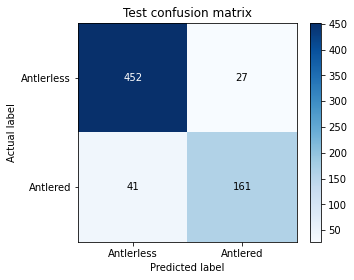


Reports and predictions saved to: X:\aanand37\Manuscript\Snapshot Wisconsin\data


In [27]:
# =============================================================================
# CELL 10 - Classification report on the held-out test set
# =============================================================================

# Select threshold using ONLY validation data.
threshold = 0.5

if CFG.tune_threshold:
    val_result = evaluate(model, make_loader(va, train=False))
    thresholds = np.linspace(0.01, 0.99, 99)

    scores = [
        f1_score(
            val_result["labels"],
            (val_result["probs"] > t).astype(int),
            labels=[0, 1],
            average="macro",
            zero_division=0,
        )
        for t in thresholds
    ]

    # If several thresholds tie, choose the one closest to 0.5.
    best_indices = np.flatnonzero(
        np.isclose(scores, np.max(scores), rtol=0, atol=1e-12)
    )
    best_idx = best_indices[
        np.argmin(np.abs(thresholds[best_indices] - 0.5))
    ]
    threshold = float(thresholds[best_idx])

    print(f"Selected threshold: {threshold:.2f}")
    print(f"Validation macro-F1: {scores[best_idx]:.4f}")

# Evaluate the test set once using the selected threshold.
test_result = evaluate(
    model,
    make_loader(te, train=False),
    threshold=threshold,
)

y_true = test_result["labels"]
y_pred = (test_result["probs"] > threshold).astype(int)

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    digits=4,
    zero_division=0,
)

print(f"\nTest classification report | threshold = {threshold:.2f}\n")
print(report_text)
print(f"Test accuracy: {test_result['acc']:.4f}")
print(f"Test macro-F1: {test_result['f1']:.4f}")

# Save the report.
report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(
    os.path.join(CFG.out_dir, "antler_classification_report.csv"),
    index_label="metric",
)

with open(
    os.path.join(CFG.out_dir, "antler_classification_report.txt"),
    "w",
    encoding="utf-8",
) as f:
    f.write(f"Decision threshold: {threshold:.4f}\n\n")
    f.write(report_text)

# Save per-row test predictions in the same order as the test dataframe.
predictions = te.copy()
predictions["prob_antlered"] = test_result["probs"]
predictions["predicted_class"] = y_pred
predictions["predicted_label"] = [
    ANTLER_NAMES[int(v)] for v in y_pred
]
predictions["correct"] = y_true == y_pred
predictions["decision_threshold"] = threshold
predictions.to_csv(
    os.path.join(CFG.out_dir, CFG.pred_file),
    index=False,
)

# Display the confusion matrix.
cm = test_result["cm"]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=ANTLER_NAMES,
    yticklabels=ANTLER_NAMES,
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Test confusion matrix",
)

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

plt.tight_layout()
plt.show()

print(f"\nReports and predictions saved to: {CFG.out_dir}")


Test classification report | decision rule: argmax

              precision    recall  f1-score   support

  Antlerless     0.9244    0.9186    0.9215       479
    Antlered     0.8098    0.8218    0.8157       202

    accuracy                         0.8899       681
   macro avg     0.8671    0.8702    0.8686       681
weighted avg     0.8904    0.8899    0.8901       681

Test accuracy: 0.8899
Test macro-F1: 0.8686


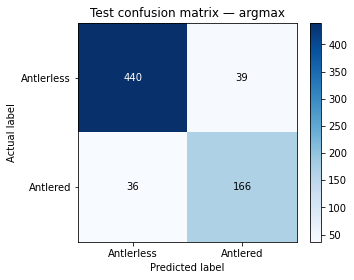


Reports and predictions saved to: X:\aanand37\Manuscript\Snapshot Wisconsin\data


In [28]:
# =============================================================================
# CELL 10 - Held-out test report using argmax (no threshold tuning)
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Run inference directly so this cell does not depend on the
# threshold-based evaluate() function.
test_loader = make_loader(te, train=False)
model.eval()

device = next(model.parameters()).device
use_amp = bool(CFG.amp and device.type == "cuda")

all_labels = []
all_predictions = []
all_prob_antlered = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)

        with torch.autocast(device.type, enabled=use_amp):
            logits = model(x)

        logits = logits.float()

        # Select whichever class has the highest model score.
        predicted_classes = logits.argmax(dim=1)

        # Retain probabilities for inspection, not class selection.
        prob_antlered = logits.softmax(dim=1)[:, 1]

        all_labels.append(y.detach().cpu().numpy())
        all_predictions.append(predicted_classes.cpu().numpy())
        all_prob_antlered.append(prob_antlered.cpu().numpy())

if not all_labels:
    raise ValueError("The test loader is empty.")

y_true = np.concatenate(all_labels).astype(int)
y_pred = np.concatenate(all_predictions).astype(int)
prob_antlered = np.concatenate(all_prob_antlered)

if len(y_true) != len(te):
    raise ValueError("Test predictions do not match the number of test rows.")

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    digits=4,
    zero_division=0,
)

print("\nTest classification report | decision rule: argmax\n")
print(report_text)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

# =============================================================================
# Save reports
# =============================================================================

os.makedirs(CFG.out_dir, exist_ok=True)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=ANTLER_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report_dict).T.to_csv(
    os.path.join(CFG.out_dir, "antler_classification_report.csv"),
    index_label="metric",
)

with open(
    os.path.join(CFG.out_dir, "antler_classification_report.txt"),
    "w",
    encoding="utf-8",
) as f:
    f.write("Decision rule: argmax\n\n")
    f.write(report_text)

# =============================================================================
# Save per-row predictions
# make_loader(te, train=False) preserves the test dataframe order.
# =============================================================================

predictions = te.copy()
predictions = predictions.drop(
    columns=["decision_threshold"],
    errors="ignore",
)
predictions["prob_antlered"] = prob_antlered
predictions["predicted_class"] = y_pred
predictions["predicted_label"] = [
    ANTLER_NAMES[int(v)] for v in y_pred
]
predictions["correct"] = y_true == y_pred
predictions["decision_rule"] = "argmax"

predictions.to_csv(
    os.path.join(CFG.out_dir, CFG.pred_file),
    index=False,
)

# =============================================================================
# Display confusion matrix
# =============================================================================

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=ANTLER_NAMES,
    yticklabels=ANTLER_NAMES,
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Test confusion matrix — argmax",
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

plt.tight_layout()
plt.show()

print(f"\nReports and predictions saved to: {CFG.out_dir}")

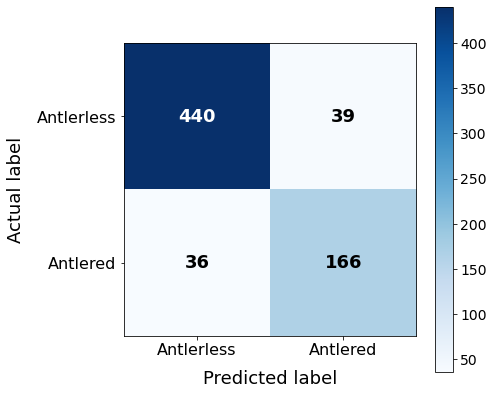

In [29]:
# =============================================================================
# Display confusion matrix with larger text
# =============================================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, cmap="Blues")

# Color bar
cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=14)


# Class labels
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(ANTLER_NAMES, fontsize=16)
ax.set_yticklabels(ANTLER_NAMES, fontsize=16)

# Axis labels and title
ax.set_xlabel("Predicted label", fontsize=18, labelpad=12)
ax.set_ylabel("Actual label", fontsize=18, labelpad=12)
ax.set_title(
    "",
    fontsize=20,
    fontweight="bold",
    pad=16,
)

# Numbers inside the matrix
for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

ax.grid(False)
plt.tight_layout()
plt.show()